# Phase 11.6 - Cross Currency Probe (GBPUSD + EURUSD)

Prueba de transferencia multi-divisa usando embeddings contextuales ya generados.

Experimentos:
- intra: entrenar/probar en la misma divisa
- cross: entrenar en una divisa y probar en la otra
- pooled: entrenar con ambas y probar por divisa

In [1]:
from pathlib import Path
import subprocess

ROOT = Path('.')
PHASE11 = ROOT / 'phases/phase11_offline_rl'
SCRIPT = PHASE11 / 'run_phase11_6_cross_currency_probe.py'
OUT = PHASE11 / 'output_phase11_6_cross_currency_probe'

res = subprocess.run(['python', str(SCRIPT)], capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError('Error running phase11.6 cross-currency probe')

Saved summary: ./phases/phase11_offline_rl/output_phase11_6_cross_currency_probe/phase11_6_summary.json
Top run: pooled_to_GBP
Top test_cum_net_pips: 15595.69874548912



In [2]:
import json
import pandas as pd

summary = json.loads((OUT / 'phase11_6_summary.json').read_text())
exp = pd.read_csv(OUT / 'phase11_6_experiments.csv')

print('Symbols:', summary['symbols'])
print('Rows:', summary['n_rows_total'])
print('Cost pips:', summary['cost_pips'])
exp

Symbols: ['EURUSD', 'GBPUSD']
Rows: 3322
Cost pips: 1.2


,run,train_symbols,val_symbols,test_symbol,n_train,n_val,n_test,best_C,best_conf_thr,val_score,val_avg_net_pips,val_cum_net_pips,test_acc_action_3,test_f1_macro_action_3,test_avg_net_pips,test_cum_net_pips,test_sharpe_like,test_trade_rate,test_win_rate_trades
0,pooled_to_GBP,"GBPUSD,EURUSD","GBPUSD,EURUSD",GBPUSD,2324,499,241,0.1,0.52,55.465172,54.923248,27406.700939,0.742739,0.694579,64.712443,15595.698745,10.899691,0.817427,0.878173
1,intra_GBP_to_GBP,GBPUSD,GBPUSD,GBPUSD,1123,241,241,0.1,0.40,57.891031,57.354755,13822.496015,0.705394,0.629760,63.913291,15403.103182,10.630414,0.875519,0.815166
2,cross_GBP_to_EUR,GBPUSD,GBPUSD,EURUSD,1123,241,258,0.1,0.40,57.891031,57.354755,13822.496015,0.720930,0.662710,52.755814,13610.999925,12.776802,0.794574,0.863415
3,pooled_to_EUR,"GBPUSD,EURUSD","GBPUSD,EURUSD",EURUSD,2324,499,258,0.1,0.52,55.465172,54.923248,27406.700939,0.682171,0.641966,50.415903,13007.302981,12.368514,0.713178,0.891304
4,cross_EUR_to_GBP,EURUSD,EURUSD,GBPUSD,1201,258,241,0.1,0.46,61.771657,61.118235,15768.504715,0.622407,0.582710,50.648966,12206.400905,7.958068,0.804979,0.742268
5,intra_EUR_to_EUR,EURUSD,EURUSD,EURUSD,1201,258,258,0.1,0.46,61.771657,61.118235,15768.504715,0.658915,0.600070,45.744563,11802.097338,10.411202,0.779070,0.830846


In [3]:
exp[['run','train_symbols','test_symbol','best_C','best_conf_thr','test_acc_action_3','test_f1_macro_action_3','test_trade_rate','test_avg_net_pips','test_cum_net_pips','test_sharpe_like']].sort_values('test_cum_net_pips', ascending=False)

,run,train_symbols,test_symbol,best_C,best_conf_thr,test_acc_action_3,test_f1_macro_action_3,test_trade_rate,test_avg_net_pips,test_cum_net_pips,test_sharpe_like
0,pooled_to_GBP,"GBPUSD,EURUSD",GBPUSD,0.1,0.52,0.742739,0.694579,0.817427,64.712443,15595.698745,10.899691
1,intra_GBP_to_GBP,GBPUSD,GBPUSD,0.1,0.40,0.705394,0.629760,0.875519,63.913291,15403.103182,10.630414
2,cross_GBP_to_EUR,GBPUSD,EURUSD,0.1,0.40,0.720930,0.662710,0.794574,52.755814,13610.999925,12.776802
3,pooled_to_EUR,"GBPUSD,EURUSD",EURUSD,0.1,0.52,0.682171,0.641966,0.713178,50.415903,13007.302981,12.368514
4,cross_EUR_to_GBP,EURUSD,GBPUSD,0.1,0.46,0.622407,0.582710,0.804979,50.648966,12206.400905,7.958068
5,intra_EUR_to_EUR,EURUSD,EURUSD,0.1,0.46,0.658915,0.600070,0.779070,45.744563,11802.097338,10.411202


In [4]:
pred = pd.read_csv(OUT / 'phase11_6_predictions.csv')
pred.head()

,window_id,symbol,start_ts,end_ts,split,ret_pips,y_action,run,pred_action,pred_conf,net_pips,cum_net_pips
0,1364,GBPUSD,2020-05-18 20:00:00,2020-11-03 04:00:00,test,-19.398928,0,intra_GBP_to_GBP,1,0.711806,-20.598928,-20.598928
1,1365,GBPUSD,2020-05-27 04:00:00,2020-11-04 11:00:00,test,95.800161,1,intra_GBP_to_GBP,1,0.888439,94.600161,74.001234
2,1366,GBPUSD,2020-06-01 04:00:00,2020-11-23 04:00:00,test,-2.000332,0,intra_GBP_to_GBP,-1,0.782964,0.800332,74.801566
3,1367,GBPUSD,2020-06-04 04:00:00,2020-12-03 22:00:00,test,-23.399591,-1,intra_GBP_to_GBP,0,0.732943,-0.000000,74.801566
4,1368,GBPUSD,2020-06-05 04:00:00,2020-12-06 21:00:00,test,-81.399679,-1,intra_GBP_to_GBP,-1,0.858529,80.199679,155.001245


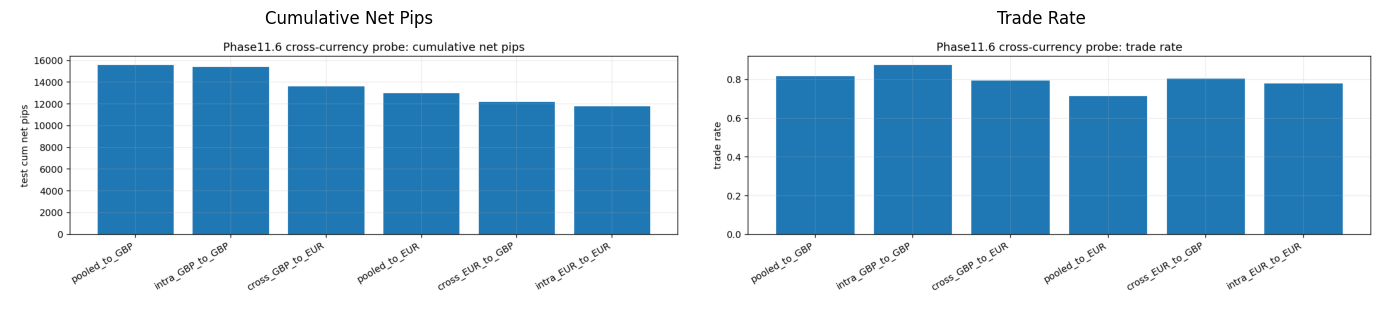

In [5]:
import matplotlib.pyplot as plt

img1 = plt.imread(OUT / 'phase11_6_cum_net_pips_by_experiment.png')
img2 = plt.imread(OUT / 'phase11_6_trade_rate_by_experiment.png')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(img1); ax[0].axis('off'); ax[0].set_title('Cumulative Net Pips')
ax[1].imshow(img2); ax[1].axis('off'); ax[1].set_title('Trade Rate')
plt.tight_layout(); plt.show()

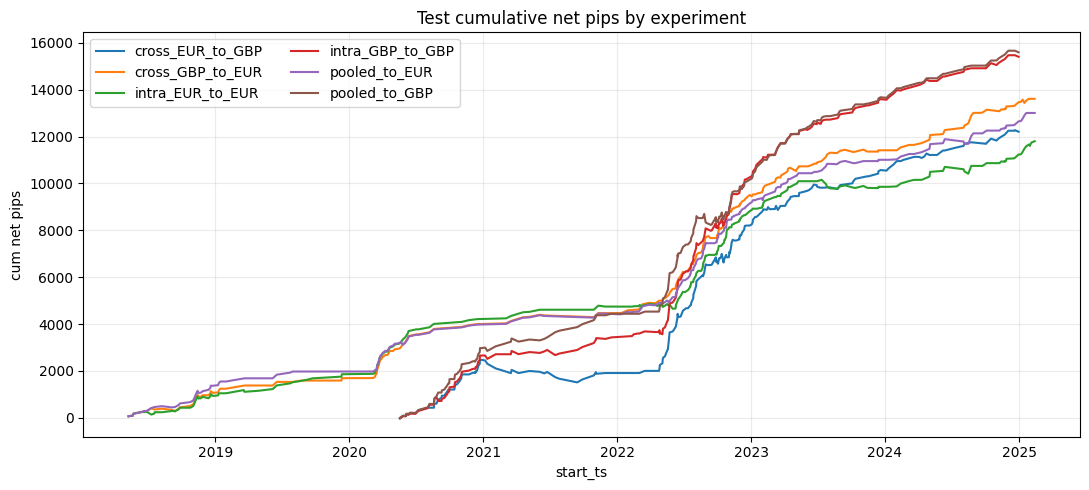

In [6]:
# Curvas acumuladas por experimento en test
import matplotlib.pyplot as plt

plt.figure(figsize=(11,5))
for run, g in pred.groupby('run'):
    gg = g.sort_values('start_ts')
    plt.plot(pd.to_datetime(gg['start_ts']), gg['cum_net_pips'], label=run)

plt.title('Test cumulative net pips by experiment')
plt.xlabel('start_ts')
plt.ylabel('cum net pips')
plt.grid(alpha=0.25)
plt.legend(loc='best', ncol=2)
plt.tight_layout()
plt.show()